In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


BLUE, ORANGE, GREEN = "#2465b3", '#eb6834', '#1baf7a'
cmap = ListedColormap([BLUE, ORANGE, GREEN])

In [2]:
movies = pd.DataFrame({
 'movie': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'],
 'fights': [9, 6, 9, 7, 4, 1, 2, 2],
 'songs': [2, 1, 4, 3, 5, 8, 9, 6],
 'genre': ['Action'] * 4 + ['Romance'] * 4,
})
movies

,movie,fights,songs,genre
0,A,9,2,Action
1,B,6,1,Action
2,C,9,4,Action
3,D,7,3,Action
4,E,4,5,Romance
5,F,1,8,Romance
6,G,2,9,Romance
7,H,2,6,Romance


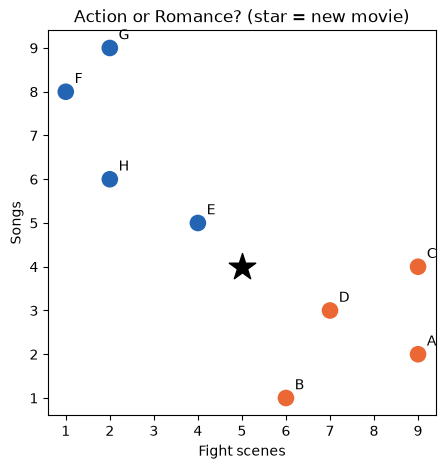

In [3]:
colors = movies['genre'].map({'Action': ORANGE, 'Romance': BLUE})
plt.figure(figsize=(5, 5))
plt.scatter(movies['fights'], movies['songs'], c=colors, s=120)
plt.scatter(5, 4, marker='*', s=400, c='black') # the new movie
for name, x, y in zip(movies['movie'], movies['fights'], movies['songs']):
 plt.text(x + 0.2, y + 0.2, name)
plt.xlabel('Fight scenes')
plt.ylabel('Songs')
plt.title('Action or Romance? (star = new movie)')
plt.show()

In [4]:
movies['distance'] = np.sqrt((movies['fights'] - 5)**2 +
                             (movies['songs'] - 4)**2)

                             

In [5]:
movies

,movie,fights,songs,genre,distance
0,A,9,2,Action,4.472136
1,B,6,1,Action,3.162278
2,C,9,4,Action,4.000000
3,D,7,3,Action,2.236068
4,E,4,5,Romance,1.414214
5,F,1,8,Romance,5.656854
6,G,2,9,Romance,5.830952
7,H,2,6,Romance,3.605551


In [10]:
k = 5

nearest = movies.sort_values('distance').head(k)

print(nearest[['movie', 'genre', 'distance']].round(2))

print()

print(nearest['genre'].value_counts().idxmax())

  movie    genre  distance
4     E  Romance      1.41
3     D   Action      2.24
1     B   Action      3.16
7     H  Romance      3.61
2     C   Action      4.00

Action


In [11]:
def knn_predict(new_fights, new_songs, data, k):
    data = data.copy()
    data['distance'] = np.sqrt((data['fights'] - new_fights)**2 +
    (data['songs'] - new_songs)**2)
    nearest = data.sort_values('distance').head(k)
    return nearest['genre'].value_counts().idxmax()

k_values = [1,3,5,8]

for k in k_values:
    print(f"K = {k}  -> Prediction: {knn_predict(5, 4, movies, k)}")

K = 1  -> Prediction: Romance
K = 3  -> Prediction: Action
K = 5  -> Prediction: Action
K = 8  -> Prediction: Romance


In [12]:
from sklearn.neighbors import KNeighborsClassifier

X_movies = movies[['fights', 'songs']]        # Feature columns
y_movies = movies['genre']

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_movies, y_movies)

new_movie = pd.DataFrame({'fights': [5], 'songs': [4]})
print(knn.predict(new_movie))
print(knn.classes_)
print(knn.predict_proba(new_movie).round(4))

['Action']
['Action' 'Romance']
[[0.6667 0.3333]]


In [13]:
movies['genre'].value_counts()

genre
Action     4
Romance    4
Name: count, dtype: int64

In [14]:
distances, positions = knn.kneighbors(new_movie)

print("distance:", distances.round(2))
print("Positions: ", positions)
movies.loc[positions[0], ['movie', 'genre']]

distance: [[1.41 2.24 3.16]]
Positions:  [[4 3 1]]


,movie,genre
4,E,Romance
3,D,Action
1,B,Action


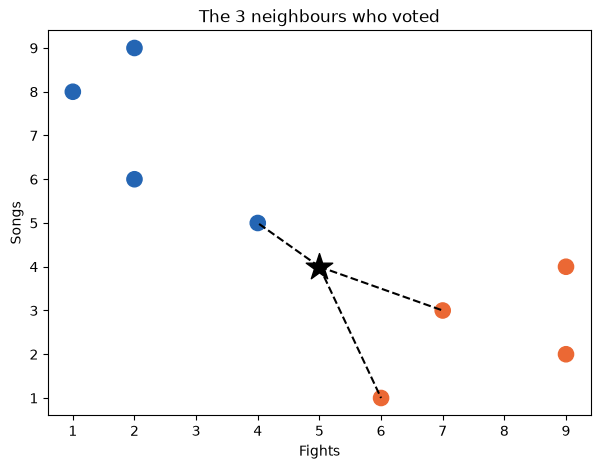

In [15]:
plt.figure(figsize=(7,5))
plt.scatter(movies['fights'], movies['songs'], c = colors, s = 120)
for p in positions[0]:
    plt.plot([5, movies.loc[p, 'fights']],[4, movies.loc[p, 'songs']], 'k--')

plt.scatter(5, 4, marker = '*', s = 400, c = 'black')
plt.xlabel('Fights')
plt.ylabel('Songs')
plt.title('The 3 neighbours who voted')
plt.show()

In [16]:
knn8 = KNeighborsClassifier(n_neighbors=8).fit(X_movies, y_movies)

print(knn8.predict_proba(new_movie))
print(knn8.predict(new_movie))


[[0.5 0.5]]
['Action']


In [17]:
knn8.classes_

array(['Action', 'Romance'], dtype=object)

## Lets meet the wine dataset

In [18]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)

df = wine.frame

print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [19]:
df.dtypes

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

In [20]:
df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [22]:
print(wine.target_names)

['class_0' 'class_1' 'class_2']


In [23]:
df['target'].value_counts().sort_index()

target
0    59
1    71
2    48
Name: count, dtype: int64

In [24]:
df.drop(columns = 'target').describe().T[['min', 'max']]

,min,max
alcohol,11.03,14.83
malic_acid,0.74,5.80
ash,1.36,3.23
alcalinity_of_ash,10.60,30.00
magnesium,70.00,162.00
total_phenols,0.98,3.88
flavanoids,0.34,5.08
nonflavanoid_phenols,0.13,0.66
proanthocyanins,0.41,3.58
color_intensity,1.28,13.00


In [25]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='target')

y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state=42, stratify=y)

print("Train size: ", X_train.shape)
print("Test size:", X_test.shape)

Train size:  (133, 13)
Test size: (45, 13)


In [26]:
df.shape

(178, 14)

Text(0.5, 1.0, 'Training wines: 2 of the 13 features')

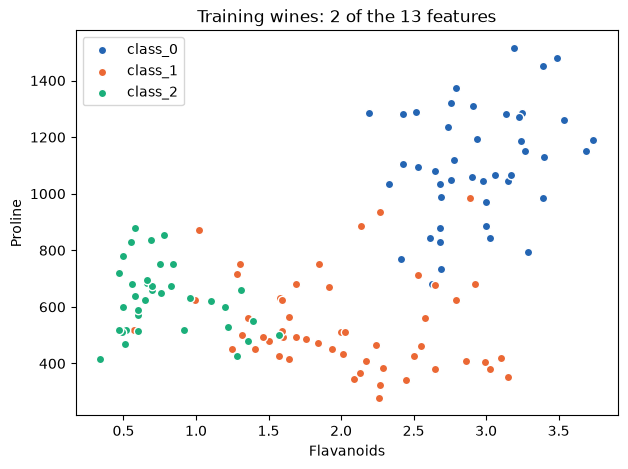

In [29]:
cols = ['flavanoids','proline']
plt.figure(figsize = (7,5))

for c, color in zip([0, 1, 2], [BLUE, ORANGE, GREEN]):
    part = X_train[y_train == c]
    plt.scatter(part['flavanoids'], part['proline'], color = color,
                edgecolors='white', label = wine.target_names[c])

plt.xlabel("Flavanoids")
plt.ylabel("Proline")
plt.legend()
plt.title("Training wines: 2 of the 13 features")

In [32]:
from sklearn.inspection import DecisionBoundaryDisplay

def plot_boundary(model, X, y, title, ax=None):
    disp = DecisionBoundaryDisplay.from_estimator(
        model, X, response_method='predict', plot_method='pcolormesh',
        cmap=cmap, vmin=0, vmax=2, alpha = 0.25, ax=ax
    )
    disp.ax_.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=cmap,
                     vmin=0, vmax=2, edgecolors='white', s = 30)
    disp.ax_.set_title(title)

5-fold CV accuracy (raw features):  0.6692


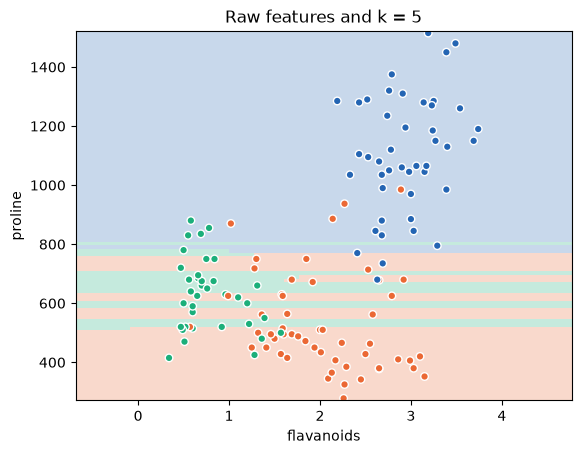

In [33]:
from sklearn.model_selection import cross_val_score

knn_raw_features = KNeighborsClassifier(n_neighbors=5)
raw_cv = cross_val_score(knn_raw_features, X_train[cols], y_train, cv=5).mean()

print("5-fold CV accuracy (raw features): ", round(raw_cv, 4))

knn_raw_features.fit(X_train[cols], y_train)
plot_boundary(knn_raw_features, X_train[cols], y_train, "Raw features and k = 5")

## Lets fix the decision boundary

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scaled_cv = cross_val_score(knn_scaled, X_train[cols], y_train, cv = 5).mean()
knn_scaled.fit(X_train[cols], y_train)
print("5 - fold cv accuracy scores (scaled features): ", round(scaled_cv, 4))

5 - fold cv accuracy scores (scaled features):  0.8652


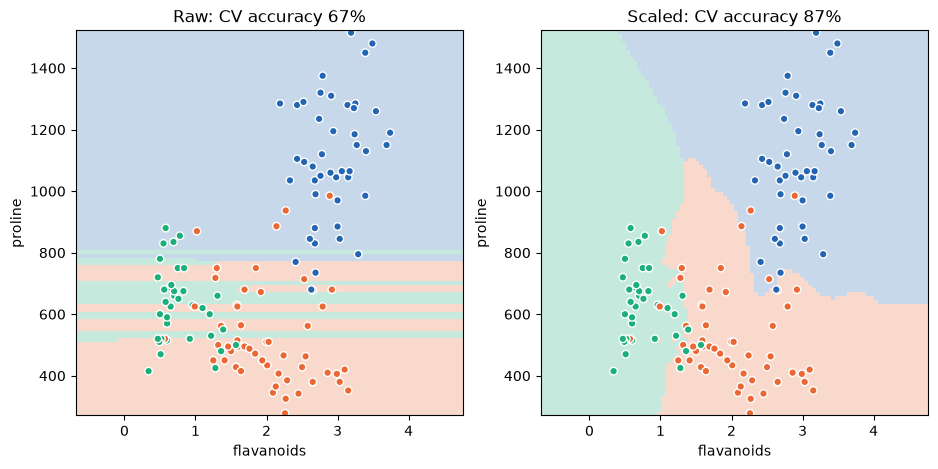

In [35]:
fig, axes = plt.subplots(1, 2, figsize = (11,5))
plot_boundary(knn_raw_features, X_train[cols], y_train,f"Raw: CV accuracy {raw_cv:.0%}", ax = axes[0])
plot_boundary(knn_scaled, X_train[cols], y_train,
              f"Scaled: CV accuracy {scaled_cv:.0%}", ax=axes[1])
plt.show()

## What did standard scaler do to our columns

In [37]:
scaled = pd.DataFrame(StandardScaler().fit_transform(X_train[cols]), columns = cols)
scaled.describe().loc[['mean', 'std', 'min', 'max']].round(2)

,flavanoids,proline
mean,-0.00,-0.00
std,1.00,1.00
min,-1.73,-1.55
max,1.83,2.53


## Now we will work on all the 13 columns

In [40]:
model_raw = KNeighborsClassifier(n_neighbors=5)
model_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

raw_13 = cross_val_score(model_raw, X_train, y_train, cv=5).mean()

scaled_13 = cross_val_score(model_scaled, X_train, y_train, cv=5).mean()

print(f"Without scaling: {raw_13:.0%}")
print(f"With scaling: {scaled_13:.0%}")



Without scaling: 68%
With scaling: 95%


## How k value changes the decision boundary

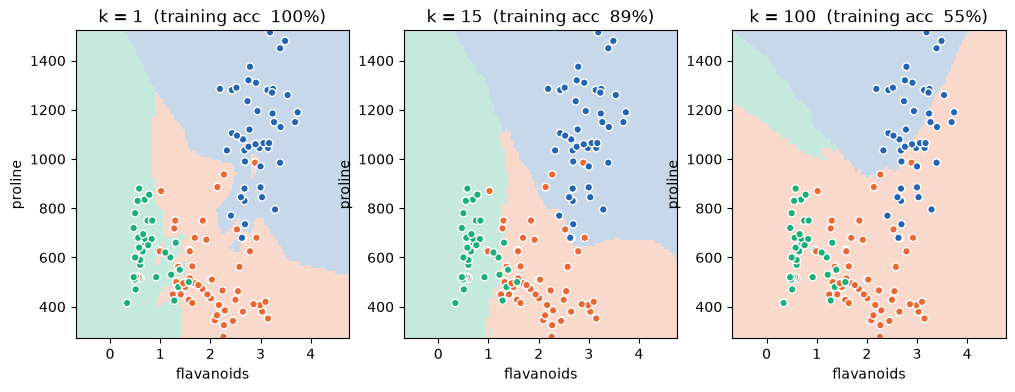

In [41]:
fig, axes = plt.subplots(1, 3, figsize = (12,4))
for ax, k in zip(axes, [1, 15, 100]):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train[cols], y_train)
    train_acc = model.score(X_train[cols], y_train)
    plot_boundary(model, X_train[cols], y_train,
                  f"k = {k}  (training acc  {train_acc:.0%})", ax=ax)

plt.show()

## Choose k with cross-validartion, not the test set

In [ ]:
k_values = range(11, 20)

cv_scores = []

for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(model, X_train, y_train, cv=5).mean())

best_k = k_values[np.argmax(cv_scores)]
print("Best K: ", best_k,  "CV accuracy: ", round(max(cv_scores), 3))

Best K:  15 CV accuracy:  0.977


## K = 15 is the best n_neighbours value

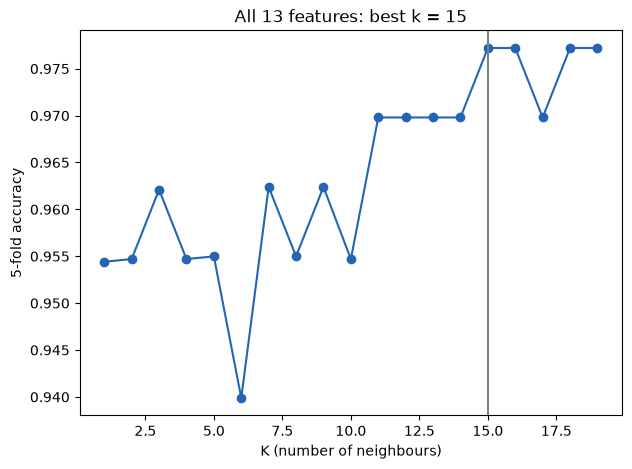

In [50]:
plt.figure(figsize = (7,5))
plt.plot(k_values, cv_scores, marker = 'o', color = BLUE)
plt.axvline(best_k, color = 'grey')
plt.xlabel('K (number of neighbours)')
plt.ylabel("5-fold accuracy")
plt.title(f"All 13 features: best k = {best_k}")
plt.show()

## Tune the model using GridSearchCV

In [58]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier()),
])

param_grid = {
    'knn__n_neighbors': list(range(1, 40)),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1,2],
}

grid = GridSearchCV(pipe, param_grid=param_grid, cv = 5)

grid.fit(X_train, y_train)
print("Best settings: ", grid.best_params_)
print("Best cv score: ", round(grid.best_score_, 3))



Best settings:  {'knn__n_neighbors': 6, 'knn__p': 1, 'knn__weights': 'uniform'}
Best cv score:  0.992


In [60]:
results = pd.DataFrame(grid.cv_results_)
show = ['param_knn__n_neighbors', 'param_knn__weights',
        'param_knn__p', 'mean_test_score']

results[show].sort_values('mean_test_score', ascending = False).head(10).round(3)

,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_score
20,6,uniform,1,0.992
0,1,uniform,1,0.985
5,2,distance,1,0.985
1,1,distance,1,0.985
16,5,uniform,1,0.977
21,6,distance,1,0.977
25,7,distance,1,0.977
24,7,uniform,1,0.977
17,5,distance,1,0.977
114,29,uniform,2,0.977


## lets test the params in the test data 

In [61]:
final_model = grid.best_estimator_

y_pred = final_model.predict(X_test)

print("Test accuracy: ", round(final_model.score(X_test, y_test), 3))
print("Correct: ", (y_pred == y_test).sum(), 'out of ', len(y_test))

Test accuracy:  0.978
Correct:  44 out of  45


              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      0.94      0.97        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



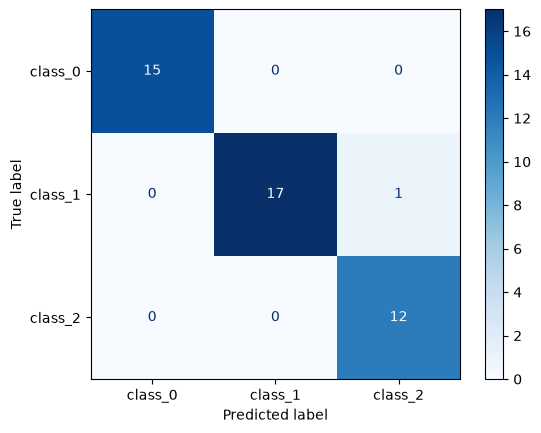

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, y_pred, target_names = wine.target_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels = wine.target_names, cmap= 'Blues')
plt.show()

## Probabilities

Unanimous vote:  31 of 45
Vote shares:  [0.33 0.67 0.  ] True class:  1


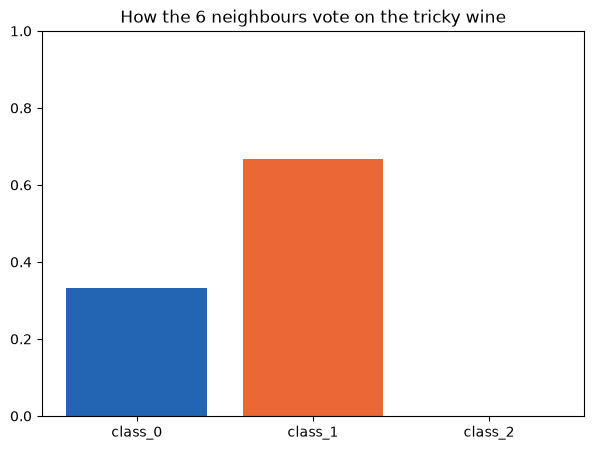

In [66]:
proba = final_model.predict_proba(X_test)
confidence = proba.max(axis = 1)
print("Unanimous vote: ", (confidence == 1).sum(), 'of', len(confidence))

i = confidence.argmin()

print('Vote shares: ', proba[i].round(2), 'True class: ', y_test.iloc[i])

k = grid.best_params_['knn__n_neighbors']

plt.figure(figsize = (7,5))
plt.bar(wine.target_names, proba[i], color = [BLUE, ORANGE, GREEN])
plt.ylim(0,1)
plt.title(f"How the {k} neighbours vote on the tricky wine")
plt.show()



## Proof that KNN is actually lazy classifier

In [ ]:
import time
from sklearn.datasets import make_classification

X_big, y_big = make_classification(n_samples = 200_000,
                                   n_features=20,
                                   random_state=42)

model = KNeighborsClassifier(n_neighbors=5)

start = time.perf_counter()
model.fit(X_big, y_big)
fit_time = time.perf_counter() - start


start = time.perf_counter()
model.predict(X_big)
predict_time = time.perf_counter() - start


print(f"Fit()   on 2 lakh rows : {fit_time:.3f} s")
print(f"predict()   on just 2lakh rows: {predict_time:.3f}")


Fit()   on 2 lakh rows : 0.021 s
predict()   on just 2,000 rows: 37.048


## Is more features better for KNN ?

In [70]:
rng = np.random.default_rng(0)
noise_counts = [0, 5, 10, 20, 100, 300]
noise_scores = []
for n in noise_counts:
    junk = rng.normal(size = (len(X_train), n))
    X_junk = np.hstack([X_train, junk])
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    noise_scores.append(cross_val_score(model, X_junk, y_train, cv =5).mean())
    print(f" {n} junk columns -> CV accuracy {noise_scores[-1]:.1%}")

 0 junk columns -> CV accuracy 95.5%
 5 junk columns -> CV accuracy 96.2%
 10 junk columns -> CV accuracy 94.0%
 20 junk columns -> CV accuracy 94.8%
 100 junk columns -> CV accuracy 81.9%
 300 junk columns -> CV accuracy 63.3%


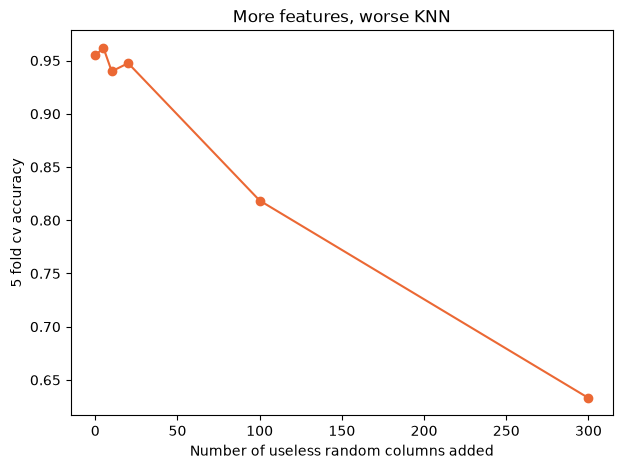

In [71]:
plt.figure(figsize = (7,5))
plt.plot(noise_counts, noise_scores, marker = 'o', color = ORANGE)
plt.xlabel("Number of useless random columns added")
plt.ylabel("5 fold cv accuracy")
plt.title("More features, worse KNN")
plt.show()

## Lets play with KNN

In [72]:
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y = digits.target

print(X.shape)
print(y.shape)

(1797, 64)
(1797,)


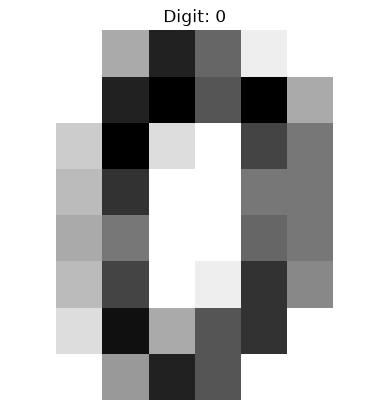

In [73]:
plt.imshow(X[0].reshape(8,8), cmap = 'gray_r')
plt.title(f"Digit: {y[0]}")
plt.axis("off")
plt.show()

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

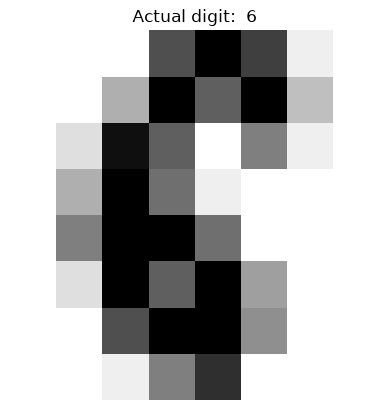

In [76]:
image_number = 36

test_image = X_test[image_number]
plt.imshow(test_image.reshape(8,8), cmap = 'gray_r')
plt.title(f"Actual digit:  {y_test[image_number]}")
plt.axis("off")
plt.show()

In [77]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

distances, indices = knn.kneighbors(
    [test_image]
)

print(y_train[indices[0]])
print(distances[0])

[6 8 6 8 8]
[23.79075451 24.2693222  24.45403852 27.51363298 29.24038303]


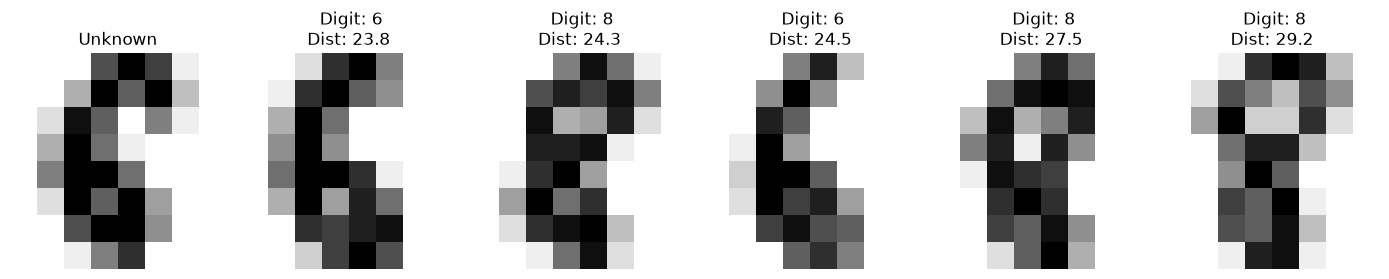

In [78]:
fig, axes = plt.subplots(1, 6, figsize = (14,3))

axes[0].imshow(test_image.reshape(8,8), cmap = 'gray_r')
axes[0].set_title("Unknown")
axes[0].axis("off")

for i, neighbor_index in enumerate(indices[0]):
    axes[i + 1].imshow(
        X_train[neighbor_index].reshape(8,8),
        cmap = 'gray_r'
    )

    axes[i+1].set_title(f" Digit: {y_train[neighbor_index]}\n"
    f"Dist: {distances[0][i]:.1f}")

    axes[i+1].axis("off")

plt.tight_layout()
plt.show()

In [79]:
prediction = knn.predict([test_image])[0]

print("Actual: ", y_test[image_number])
print("Predicted: ", prediction)

Actual:  6
Predicted:  8
